<a href="https://colab.research.google.com/github/padmashree07-sudo/MLA0201-P.PADMASHREE-fundamentals-of-machine-learning/blob/main/EXP_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


After example 1 (yes):
  S = ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
  G = [['?', '?', '?', '?', '?', '?']]

After example 2 (yes):
  S = ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
  G = [['?', '?', '?', '?', '?', '?']]

After example 3 (no):
  S = ['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
  G = [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', 'Same']]

After example 4 (yes):
  S = ['Sunny', 'Warm', '?', 'Strong', '?', '?']
  G = [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?']]

Final specific boundary S: ['Sunny', 'Warm', '?', 'Strong', '?', '?']
Final general boundary  G: [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?']]


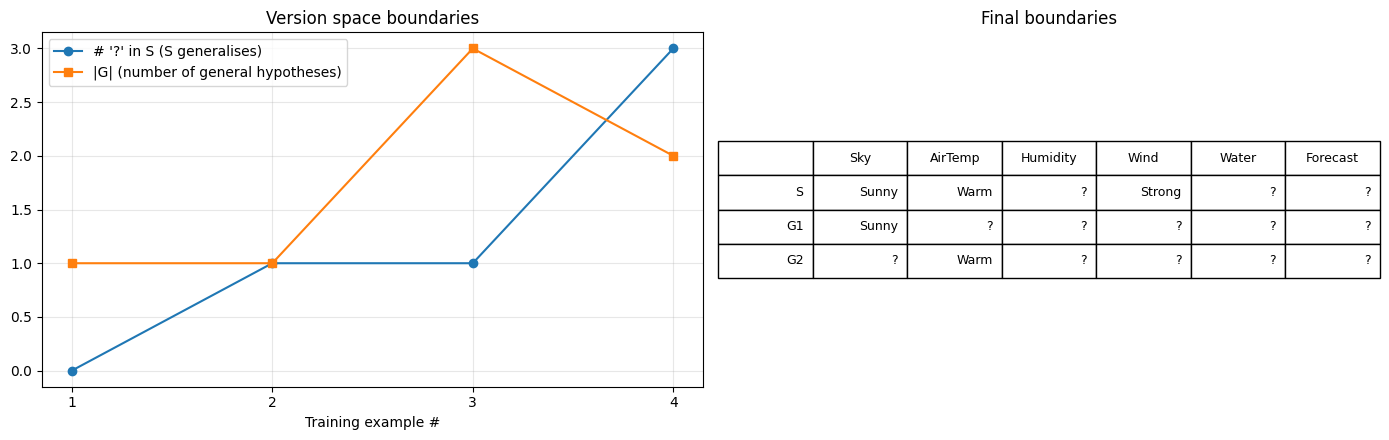

In [1]:
"""Experiment 2: Candidate-Elimination algorithm with matplotlib."""
import csv
import matplotlib.pyplot as plt

def load_csv(path):
    with open(path) as f:
        rows = list(csv.reader(f))
    return rows[0], rows[1:]

header = ["Sky", "AirTemp", "Humidity", "Wind", "Water", "Forecast", "EnjoySport"]
data = [
    ["Sunny", "Warm", "Normal", "Strong", "Warm", "Same",   "Yes"],
    ["Sunny", "Warm", "High",   "Strong", "Warm", "Same",   "Yes"],
    ["Rainy", "Cold", "High",   "Strong", "Warm", "Change", "No"],
    ["Sunny", "Warm", "High",   "Strong", "Cool", "Change", "Yes"],
]
# header, data = load_csv("enjoysport.csv")   # <- uncomment to use your CSV

n = len(header) - 1
domains = [sorted({row[i] for row in data}) for i in range(n)]

def covers(h, x):
    return all(a == "?" or a == b for a, b in zip(h, x))

def more_general(h1, h2):          # is h1 >= h2 ?
    return all(a == "?" or a == b or b == "0" for a, b in zip(h1, h2))

S = ["0"] * n
G = [["?"] * n]
size_S, size_G = [], []

for t, row in enumerate(data, 1):
    x, label = row[:-1], row[-1].lower()
    if label == "yes":
        G = [g for g in G if covers(g, x)]
        for i in range(n):
            if S[i] == "0":
                S[i] = x[i]
            elif S[i] != x[i]:
                S[i] = "?"
    else:
        new_G = []
        for g in G:
            if not covers(g, x):
                new_G.append(g)
            else:
                for i in range(n):
                    if g[i] == "?":
                        for v in domains[i]:
                            if v != x[i]:
                                h = g.copy()
                                h[i] = v
                                if more_general(h, S):
                                    new_G.append(h)
        # keep only maximally general, unique hypotheses
        unique = []
        for h in new_G:
            if h not in unique:
                unique.append(h)
        G = [h for h in unique
             if not any(h != o and more_general(o, h) for o in unique)]

    size_S.append(sum(1 for v in S if v == "?"))   # '?' count in S
    size_G.append(len(G))
    print(f"\nAfter example {t} ({label}):")
    print("  S =", S)
    print("  G =", G)

print("\nFinal specific boundary S:", S)
print("Final general boundary  G:", G)

# ---- Plots --------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
steps = range(1, len(data) + 1)

ax = axes[0]
ax.plot(steps, size_S, marker="o", label="# '?' in S (S generalises)")
ax.plot(steps, size_G, marker="s", label="|G| (number of general hypotheses)")
ax.set_xticks(list(steps))
ax.set_xlabel("Training example #")
ax.set_title("Version space boundaries")
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
ax.axis("off")
ax.set_title("Final boundaries")
cells = [["S"] + S] + [[f"G{i+1}"] + g for i, g in enumerate(G)]
tbl = ax.table(cellText=cells, colLabels=[""] + header[:-1], loc="center")
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 2)

plt.tight_layout()
plt.show()